In [1]:
import os
import zipfile
import random
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

In [6]:

# Install KaggleHub
%pip install kagglehub



In [7]:

import kagglehub

# Download dataset using KaggleHub
path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset path:", path)



Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset path: /kaggle/input/chest-xray-pneumonia


In [10]:

import os

# Find the folder containing the training images
data_path = "/kaggle/input/chest-xray-pneumonia/chest_xray"

# Training folders
normal_path = os.path.join(data_path, "train", "NORMAL")
pneumonia_path = os.path.join(data_path, "train", "PNEUMONIA")

# Count images
normal_images = os.listdir(normal_path)
pneumonia_images = os.listdir(pneumonia_path)

print("Number of Normal images:", len(normal_images))
print("Number of Pneumonia images:", len(pneumonia_images))


Number of Normal images: 1341
Number of Pneumonia images: 3875


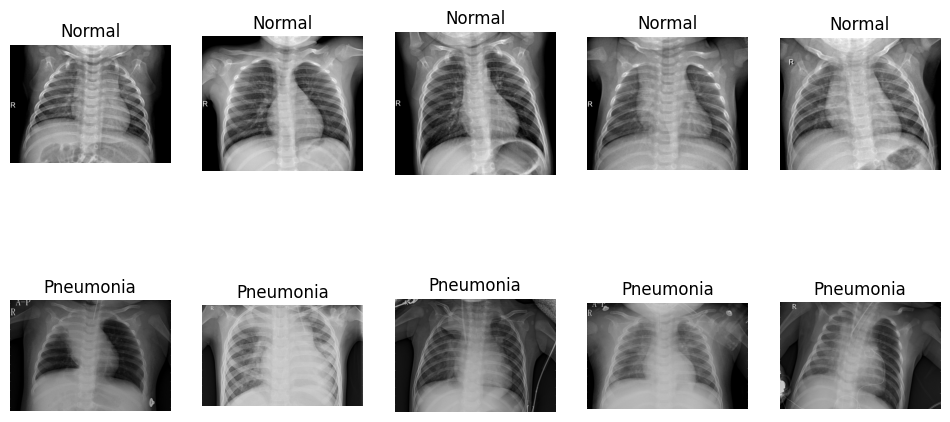

In [11]:

# Display 5 random images from each class

plt.figure(figsize=(12, 6))

# Normal images
for i in range(5):
    img_name = random.choice(normal_images)
    img_path = os.path.join(normal_path, img_name)

    img = Image.open(img_path)

    plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title("Normal")
    plt.axis("off")

# Pneumonia images
for i in range(5):
    img_name = random.choice(pneumonia_images)
    img_path = os.path.join(pneumonia_path, img_name)

    img = Image.open(img_path)

    plt.subplot(2, 5, i + 6)
    plt.imshow(img, cmap="gray")
    plt.title("Pneumonia")
    plt.axis("off")

plt.show()


In [12]:

# Image size
img_size = 128

images = []
labels = []

# Process Normal images
for file in normal_images:
    img_path = os.path.join(normal_path, file)

    img = Image.open(img_path).convert("L")
    img = img.resize((img_size, img_size))

    images.append(np.array(img))
    labels.append(0)

# Process Pneumonia images
for file in pneumonia_images:
    img_path = os.path.join(pneumonia_path, file)

    img = Image.open(img_path).convert("L")
    img = img.resize((img_size, img_size))

    images.append(np.array(img))
    labels.append(1)

# Convert lists into arrays
images = np.array(images)
labels = np.array(labels)

# Normalize pixel values
images = images / 255.0

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)


Images shape: (5216, 128, 128)
Labels shape: (5216,)


In [13]:

# Split 70% for training and 30% for validation/testing
X_train, X_temp, y_train, y_temp = train_test_split(
    images,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Split remaining 30% equally into validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))


Training images: 3651
Validation images: 782
Testing images: 783


In [14]:
%pip install scikit-image

In [15]:
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

import numpy as np

hog_features = []
lbp_features = []
glcm_features = []

for img in images:

    # Convert image to 8-bit grayscale
    img = (img * 255).astype("uint8")

    # HOG features
    hog_feature = hog(
        img,
        orientations=8,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2)
    )
    hog_features.append(hog_feature)

    # LBP features
    lbp = local_binary_pattern(img, 8, 1, method="uniform")
    lbp_hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, 11),
        range=(0, 10)
    )
    lbp_hist = lbp_hist / (lbp_hist.sum() + 1e-7)
    lbp_features.append(lbp_hist)

    # GLCM features
    glcm = graycomatrix(
        img,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    contrast = graycoprops(glcm, "contrast")[0, 0]
    correlation = graycoprops(glcm, "correlation")[0, 0]
    energy = graycoprops(glcm, "energy")[0, 0]
    homogeneity = graycoprops(glcm, "homogeneity")[0, 0]

    glcm_features.append([
        contrast,
        correlation,
        energy,
        homogeneity
    ])

# Convert feature lists to arrays
hog_features = np.array(hog_features)
lbp_features = np.array(lbp_features)
glcm_features = np.array(glcm_features)

print("HOG feature shape:", hog_features.shape)
print("LBP feature shape:", lbp_features.shape)
print("GLCM feature shape:", glcm_features.shape)

HOG feature shape: (5216, 1568)
LBP feature shape: (5216, 10)
GLCM feature shape: (5216, 4)


In [16]:
# Add channel dimension
X_train_cnn = X_train.reshape(-1, 128, 128, 1)
X_val_cnn = X_val.reshape(-1, 128, 128, 1)
X_test_cnn = X_test.reshape(-1, 128, 128, 1)

print("Training shape:", X_train_cnn.shape)
print("Validation shape:", X_val_cnn.shape)
print("Testing shape:", X_test_cnn.shape)

Training shape: (3651, 128, 128, 1)
Validation shape: (782, 128, 128, 1)
Testing shape: (783, 128, 128, 1)


In [17]:

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [18]:

# Create CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model structure
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,391,873 (28.20 MB)

 Trainable params: 7,391,873 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:

# Stop training if validation accuracy stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train_cnn,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_cnn, y_val),
    callbacks=[early_stop]
)


Epoch 1/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 104s 879ms/step - accuracy: 0.8535 - loss: 0.3407 - val_accuracy: 0.9514 - val_loss: 0.1384
Epoch 2/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 95s 823ms/step - accuracy: 0.9362 - loss: 0.1705 - val_accuracy: 0.9540 - val_loss: 0.1034
Epoch 3/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 94s 817ms/step - accuracy: 0.9518 - loss: 0.1261 - val_accuracy: 0.9425 - val_loss: 0.1490
Epoch 4/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 94s 818ms/step - accuracy: 0.9510 - loss: 0.1266 - val_accuracy: 0.9668 - val_loss: 0.0973
Epoch 5/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 93s 812ms/step - accuracy: 0.9660 - loss: 0.0959 - val_accuracy: 0.9642 - val_loss: 0.0900
Epoch 6/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 95s 831ms/step - accuracy: 0.9737 - loss: 0.0814 - val_accuracy: 0.9693 - val_loss: 0.0806
Epoch 7/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 149s 892ms/step - accuracy: 0.9721 - loss: 0.0737 - val_accuracy: 0.9744 - val_loss: 0.0769
Epoch 8/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 94s 821ms/step - accuracy: 0.9759 - loss:

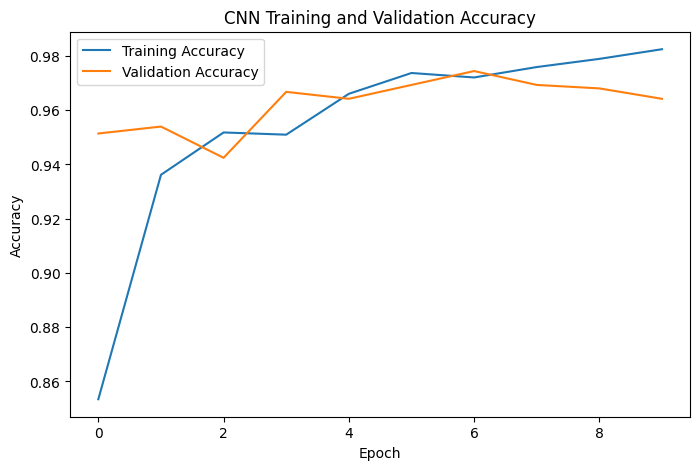

In [20]:

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [21]:

# Evaluate model on test data
test_loss, test_accuracy = model.evaluate(X_test_cnn, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


25/25 ━━━━━━━━━━━━━━━━━━━━ 9s 347ms/step - accuracy: 0.9591 - loss: 0.0981
Test Loss: 0.09809116274118423
Test Accuracy: 0.9591315388679504


In [22]:

from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, roc_auc_score

# Predict probabilities for test images
y_pred_prob = model.predict(X_test_cnn)

# Convert probabilities into class labels
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auroc = roc_auc_score(y_test, y_pred_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("AUROC:", auroc)


25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 280ms/step
Accuracy: 0.9591315453384419
Precision: 0.9807692307692307
Recall: 0.9639175257731959
F1 Score: 0.9722703639514731
AUROC: 0.9930074712348909


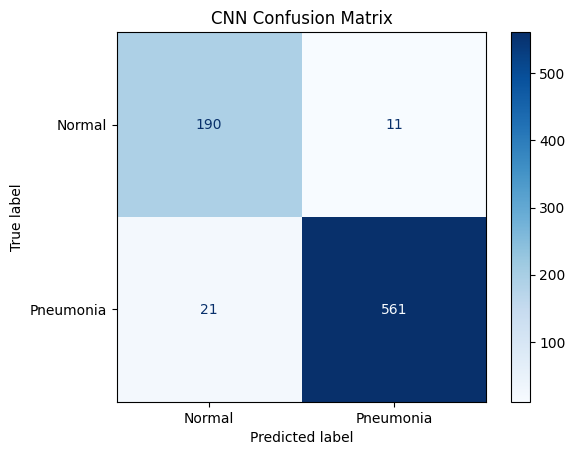

Confusion Matrix:
[[190  11]
 [ 21 561]]


In [23]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot(cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


In [24]:
from sklearn.metrics import classification_report

# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Pneumonia"]
)

print("CNN Classification Report:")
print(report)

CNN Classification Report:
              precision    recall  f1-score   support

      Normal       0.90      0.95      0.92       201
   Pneumonia       0.98      0.96      0.97       582

    accuracy                           0.96       783
   macro avg       0.94      0.95      0.95       783
weighted avg       0.96      0.96      0.96       783

